<a href="https://www.kaggle.com/code/mobeenfatimah/santa-2026-icefire-strong-start?scriptVersionId=371636928" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div style="border-radius:16px;padding:30px 34px;background:linear-gradient(115deg,#8ac4d0 0%,#377fd0 18%,#3d3b6d 38%,#1f1e1e 50%,#672a39 62%,#ce4338 82%,#f5a36a 100%);color:#fff;font-family:Inter,'Segoe UI',Helvetica,Arial,sans-serif;box-shadow:0 8px 28px rgba(0,0,0,.35)">
<div style="font-size:12px;letter-spacing:5px;text-transform:uppercase;opacity:.9">Santa 2026 &middot; The Elf Calculator</div>
<div style="font-size:40px;font-weight:800;line-height:1.15;margin-top:8px">IceFire Strong Start</div>
<div style="font-size:16px;margin-top:10px;max-width:780px;opacity:.96">Every public program bank replayed and merged &middot; CP-SAT recombination of the arithmetic graph &middot; register re-allocation &middot; strictly shorter than the best public submission</div>
</div>

**What this notebook does, in one paragraph.** It reads every program bank attached as input, replays every
single program with an independent referee, keeps the shortest valid program for each puzzle (*best-of*), and then
tries to shorten each puzzle further with an exact **CP-SAT recombination** of its arithmetic graph followed by a
**register re-allocation** into the 48 registers. A new program replaces the best-of program only if it is
*strictly* shorter and passes the replay again, so the final file can never be longer than the best attached bank —
and it is strictly shorter as soon as the optimizer finds one saving. Section 4 also looks at *where* the
instructions go, which is the most useful thing to know before writing your own solver.

| step | what happens | guarantee |
|---|---|---|
| 1 · referee | exact replay of the calculator rules | every program is checked, nothing is trusted |
| 3 · best-of | shortest valid program per puzzle over all banks | ≤ every attached bank |
| 5 · IceFire optimizer | CP-SAT recombination + register re-allocation | only strict, re-validated improvements |
| 6 · submission | file written, read back and replayed again | the printed score is the file's score |

The run is deterministic: CP-SAT uses one worker, a fixed seed and a *deterministic* time limit.

In [1]:
import csv, json, math, os, sys, time, heapq, multiprocessing as mp
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, Markdown, display

try:
    from ortools.sat.python import cp_model
except ImportError:  # internet-enabled sessions only
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ortools"], check=True)
    from ortools.sat.python import cp_model
import ortools

csv.field_size_limit(sys.maxsize)
INPUT = Path(os.environ.get("ICEFIRE_INPUT", "/kaggle/input"))
WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
CPUS = os.cpu_count() or 1

# ---- IceFire theme -------------------------------------------------------------------------
ICEFIRE = sns.color_palette("icefire", as_cmap=True)
PAL = sns.color_palette("icefire", 13).as_hex()
ICE, FIRE, DEEP_ICE, DEEP_FIRE = PAL[1], PAL[11], PAL[3], PAL[9]
BG, PANEL, INK, MUTED, GRID = "#12121a", "#181824", "#ece9f5", "#a7a3b8", "#2a2a3c"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "grid.color": GRID, "grid.linestyle": "-", "grid.linewidth": 0.6, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "font.family": "DejaVu Sans", "figure.dpi": 110, "axes.axisbelow": True,
})
from matplotlib.colors import ListedColormap
# icefire without its near-black centre: readable on a dark background
ICEFIRE_BRIGHT = ListedColormap(np.vstack([ICEFIRE(np.linspace(0.0, 0.36, 128)), ICEFIRE(np.linspace(0.64, 1.0, 128))]))

def icefire(n, lo=0.0, hi=1.0):
    """n colours sampled from ice (lo) to fire (hi), skipping the near-black centre."""
    xs = np.linspace(lo, hi, n)
    xs = np.where(np.abs(xs - 0.5) < 0.12, np.where(xs < 0.5, 0.38, 0.62), xs)
    return [ICEFIRE(x) for x in xs]

def card(label, value, sub="", grad=("#377fd0", "#3d3b6d")):
    return (f'<div style="flex:1;min-width:190px;border-radius:14px;padding:16px 20px;color:#fff;'
            f'background:linear-gradient(135deg,{grad[0]},{grad[1]});box-shadow:0 4px 14px rgba(0,0,0,.25)">'
            f'<div style="font-size:11px;letter-spacing:3px;text-transform:uppercase;opacity:.85">{label}</div>'
            f'<div style="font-size:28px;font-weight:800;margin-top:4px">{value}</div>'
            f'<div style="font-size:12px;opacity:.85">{sub}</div></div>')

def cards(*items):
    display(HTML('<div style="display:flex;gap:14px;flex-wrap:wrap;font-family:Inter,Segoe UI,sans-serif">'
                 + "".join(items) + "</div>"))

print(f"{CPUS} CPUs | ortools {ortools.__version__} | input: {INPUT}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 6.33.6 which is incompatible.


4 CPUs | ortools 9.15.6755 | input: /kaggle/input


<div style="border-left:6px solid #377fd0;background:linear-gradient(90deg,rgba(55,127,208,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#377fd0;font-weight:700">1 · referee</span><div style="font-size:24px;font-weight:800;margin-top:2px">The calculator and an independent replay</div></div>

Each puzzle starts with a few positive integers in a bank of **48 registers**. An instruction `["op", i, j, d]`
writes `regs[i] op regs[j]` into register `d` (both operands are read before the write). Values must stay positive
integers, division must be exact, and every intermediate value must stay within the puzzle's `value_limit`. A target
counts as soon as it appears in any register. The score is the total number of instructions — **lower is better**,
and a single invalid program rejects the whole submission. The referee below implements exactly these rules.

In [2]:
def load_puzzles(path):
    with open(path, encoding="utf-8", newline="") as f:
        return {r["id"]: (tuple(json.loads(r["starting_values"])), tuple(json.loads(r["targets"])),
                          int(r["value_limit"])) for r in csv.DictReader(f)}

PUZZLE_FILE = next(p for p in sorted(INPUT.rglob("puzzles.csv")))
PUZZLES = load_puzzles(PUZZLE_FILE)
assert set(PUZZLES) == {f"scored_{i:04d}" for i in range(1, 1001)}


class Invalid(ValueError):
    pass


def parse(cell):
    if not isinstance(cell, str) or len(cell.encode("utf-8")) > 131072:
        raise Invalid("cell missing or above 128 KiB")
    prog = json.loads(cell)
    if not isinstance(prog, list) or len(prog) > 4096:
        raise Invalid("expected an array of at most 4096 instructions")
    for ins in prog:
        if (not isinstance(ins, list) or len(ins) != 4 or ins[0] not in ("+", "-", "*", "/")
                or any(type(k) is not int or not 0 <= k < 48 for k in ins[1:])):
            raise Invalid(f"malformed instruction {ins!r}")
    return prog


def replay(puzzle, prog):
    """Number of instructions of a valid program; raises Invalid otherwise."""
    starts, targets, cap = puzzle
    regs = list(starts) + [None] * (48 - len(starts))
    seen = set(starts)
    for step, (op, i, j, d) in enumerate(prog, 1):
        a, b = regs[i], regs[j]
        if a is None or b is None:
            raise Invalid(f"step {step}: undefined register")
        if op == "+":
            v = a + b
        elif op == "-":
            v = a - b
        elif op == "*":
            v = a * b
        elif a % b == 0:
            v = a // b
        else:
            raise Invalid(f"step {step}: inexact division")
        if not 1 <= v <= cap:
            raise Invalid(f"step {step}: value {v} outside 1..{cap}")
        regs[d] = v
        seen.add(v)
    if not seen.issuperset(targets):
        raise Invalid("missing targets")
    return len(prog)


# the worked example from the competition page: 3/3=1, 3-1=2, 3+2=5, 3+5=8
assert replay(((3,), (1, 2, 5, 8), 9), parse('[["/",0,0,1],["-",0,1,2],["+",0,2,3],["+",0,3,4]]')) == 4
for bad in ('[["-",0,0,1]]', '[["*",0,0,1],["*",1,1,1]]', '[["+",2,2,1]]', '[]'):
    try:
        replay(((3,), (1, 2, 5, 8), 9), parse(bad))
        raise AssertionError(bad)
    except Invalid:
        pass
NEW_TARGETS = sum(len(set(t) - set(s)) for s, t, _ in PUZZLES.values())
print(f"{len(PUZZLES):,} puzzles · {NEW_TARGETS:,} targets to build · referee self-test passed")

1,000 puzzles · 26,898 targets to build · referee self-test passed


<div style="border-left:6px solid #ce4338;background:linear-gradient(90deg,rgba(206,67,56,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#ce4338;font-weight:700">2 · landscape</span><div style="font-size:24px;font-weight:800;margin-top:2px">What the 1,000 puzzles look like</div></div>

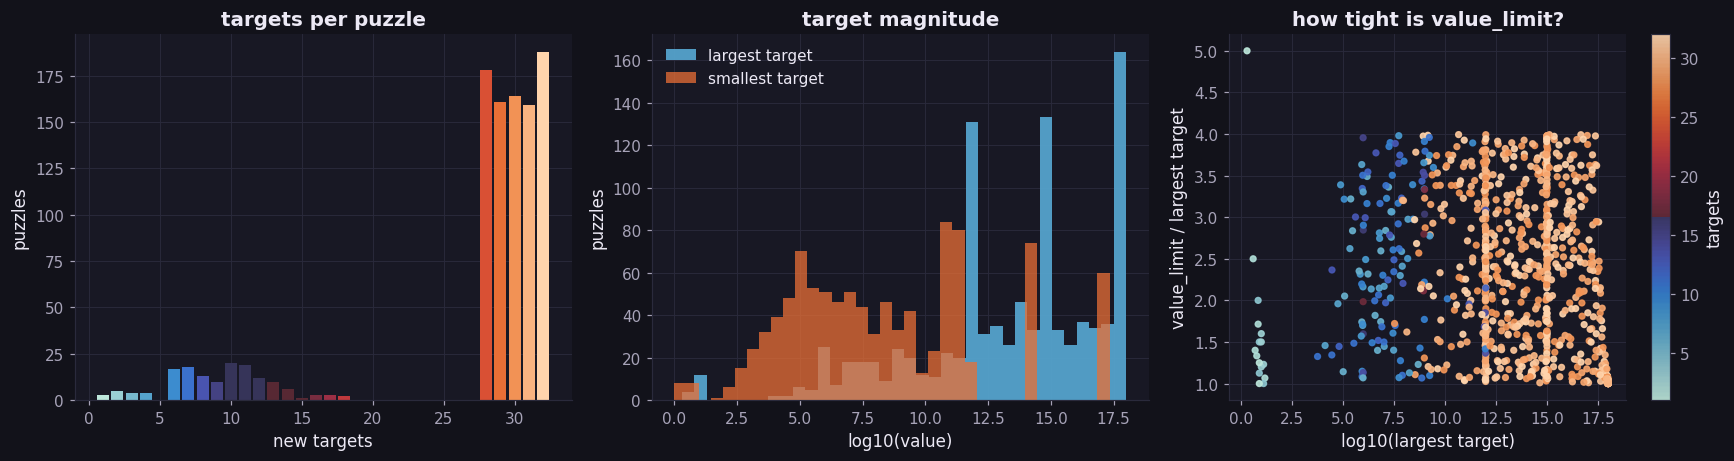

**850** puzzles ask for 28–32 targets, typically between 10^12 and 10^18, built from 1–8 starting values that never exceed 1,998. The limit leaves only 2.2× headroom above the largest target on a typical puzzle, so a program cannot overshoot far and come back.

In [3]:
rows = []
for pid, (s, t, cap) in PUZZLES.items():
    rows.append(dict(id=pid, n_start=len(s), n_targets=len(set(t) - set(s)), log_tmax=math.log10(t[-1]),
                     log_tmin=math.log10(t[0]), headroom=cap / t[-1], log_smax=math.log10(s[-1])))
landscape = pd.DataFrame(rows).set_index("id")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
cnt = landscape.n_targets.value_counts().sort_index()
ax.bar(cnt.index, cnt.values, color=icefire(len(cnt)), width=0.85)
ax.set(title="targets per puzzle", xlabel="new targets", ylabel="puzzles")
ax = axes[1]
ax.hist(landscape.log_tmax, bins=36, color=ICE, alpha=0.95, label="largest target")
ax.hist(landscape.log_tmin, bins=36, color=FIRE, alpha=0.75, label="smallest target")
ax.set(title="target magnitude", xlabel="log10(value)", ylabel="puzzles"); ax.legend()
ax = axes[2]
sc = ax.scatter(landscape.log_tmax, landscape.headroom, c=landscape.n_targets, cmap=ICEFIRE_BRIGHT, s=14, alpha=0.9)
ax.set(title="how tight is value_limit?", xlabel="log10(largest target)", ylabel="value_limit / largest target")
cb = fig.colorbar(sc, ax=ax); cb.set_label("targets", color=INK); cb.ax.yaxis.set_tick_params(color=MUTED)
plt.tight_layout(); plt.show()

big = landscape.query("n_targets >= 28").shape[0]
display(Markdown(f"**{big}** puzzles ask for 28–32 targets, typically between 10^12 and 10^18, built from 1–8 "
                 f"starting values that never exceed {10 ** landscape.log_smax.max():,.0f}. The limit leaves only "
                 f"{landscape.headroom.median():.1f}× headroom above the largest target on a typical puzzle, "
                 "so a program cannot overshoot far and come back."))

<div style="border-left:6px solid #377fd0;background:linear-gradient(90deg,rgba(55,127,208,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#377fd0;font-weight:700">3 · best-of</span><div style="font-size:24px;font-weight:800;margin-top:2px">Public program banks, replayed and merged</div></div>

Every CSV with the header `id,program` found under the input directory is treated as a *bank*. Each of its
programs is replayed by the referee; an invalid program is simply never used. For every puzzle the shortest valid
program across all banks is kept. The banks attached to this notebook are the public notebooks credited at the end.

In [4]:
def read_bank(path):
    with open(path, encoding="utf-8", newline="") as f:
        r = csv.reader(f)
        if next(r, None) != ["id", "program"]:
            return None
        return {row[0]: row[1] for row in r if len(row) == 2}


def bank_name(path):
    return path.parent.name if path.parent != INPUT else path.stem


banks = {}
for path in sorted(INPUT.rglob("*.csv")):
    if path.name in ("sample_submission.csv", "puzzles.csv", "practice_puzzles.csv"):
        continue
    rows = read_bank(path)
    if rows:
        name = bank_name(path)
        if name in banks:
            name = f"{path.parent.parent.name}/{name}/{path.stem}"
        banks[name] = rows

candidates = defaultdict(dict)      # pid -> {program text: (length, parsed program)}
table = []
for name, rows in banks.items():
    total, ok = 0, 0
    for pid, puzzle in PUZZLES.items():
        cell = rows.get(pid)
        if cell is None:
            continue
        try:
            prog = parse(cell)
            n = replay(puzzle, prog)
        except (Invalid, ValueError, TypeError):
            continue
        ok += 1
        total += n
        candidates[pid].setdefault(cell, (n, prog))
    table.append(dict(bank=name, valid=ok, score=total if ok == len(PUZZLES) else None))

best_of = {pid: min(c.values(), key=lambda x: x[0]) for pid, c in candidates.items()}
assert set(best_of) == set(PUZZLES), "some puzzle has no valid program in the attached banks"
BEST_OF = sum(n for n, _ in best_of.values())
winner = Counter()                   # which bank supplies a shortest program (first bank in sorted order wins ties)
for pid, (n, _) in best_of.items():
    for name, rows in banks.items():
        cell = rows.get(pid)
        if cell is not None and cell in candidates[pid] and candidates[pid][cell][0] == n:
            winner[name] += 1
            break
scoreboard = pd.DataFrame(table)
scoreboard["best programs"] = scoreboard.bank.map(winner).fillna(0).astype(int)
scoreboard = scoreboard.sort_values("score", na_position="last").reset_index(drop=True)
BEST_BANK = int(scoreboard.score.min())
display(scoreboard.style.format({"score": "{:,.0f}"}, na_rep="incomplete").hide(axis="index"))

bank,valid,score,best programs
santa-2026-starter-notebook,1000,"136,053",5
santa-2026-fast-validator-eda-sota-baseline,1000,"136,060",995
best-of-public-elf-optimizer,1000,"136,096",0
santa-2026-elf-calculator-verified-portfolio,1000,"136,829",0
elf-calc-shared-helpers-chain-resynthesis,1000,"137,708",0
santa-2026-exact-portfolio-frontier-138441,1000,"137,738",0
public-merge,1000,"137,794",0
elf-calculator-best-of-public-merge-polish,1000,"137,919",0
santa-2026-joint-recipes-for-large-puzzles,1000,"138,273",0
santa-2026-arithmetic-graph-rewrites,1000,"138,485",0


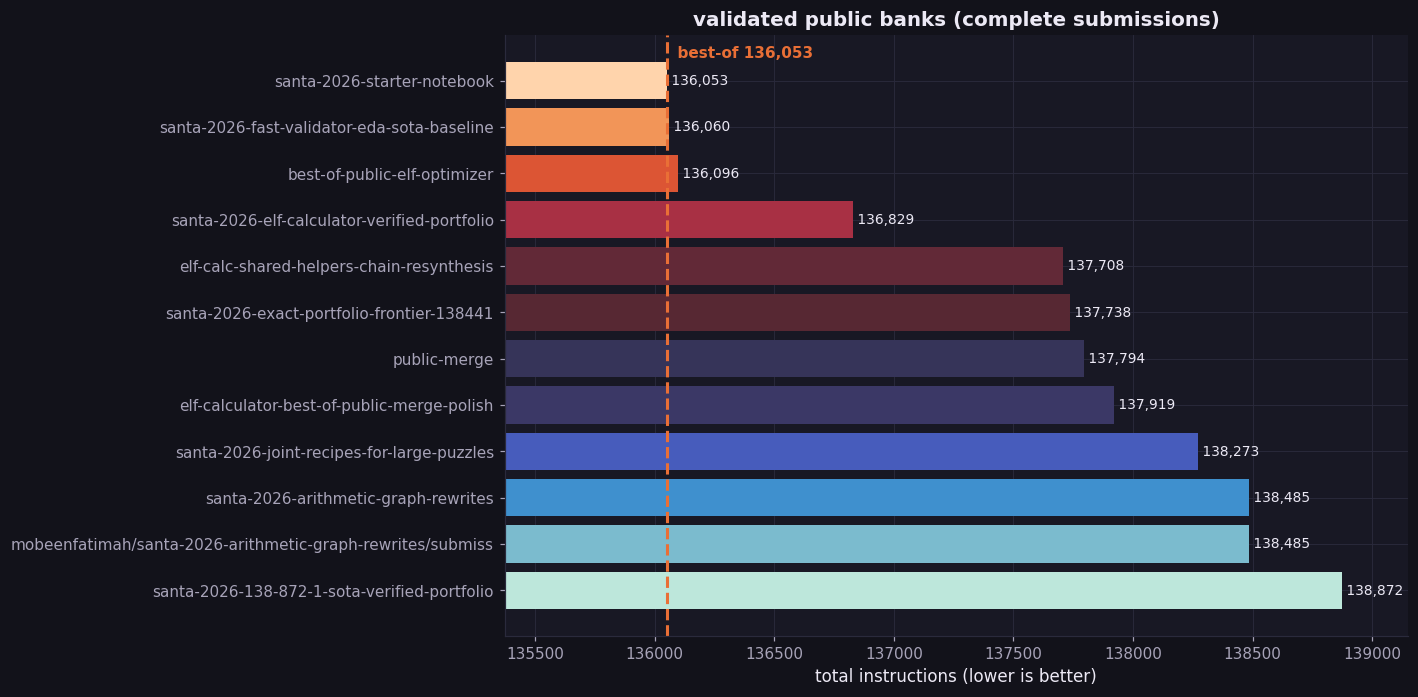

In [5]:
full = scoreboard.dropna().head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 0.42 * len(full) + 1.4))
colors = icefire(len(full), 0.0, 1.0)
ax.barh(full.bank.str.slice(0, 58), full.score, color=colors)
lo = min(full.score.min(), BEST_OF) * 0.995
ax.set_xlim(lo, full.score.max() * 1.002)
ax.axvline(BEST_OF, color=FIRE, lw=2, ls="--")
ax.text(BEST_OF, len(full) - 0.4, f"  best-of {BEST_OF:,}", color=FIRE, va="center", fontweight="bold")
for y, v in enumerate(full.score):
    ax.text(v, y, f" {v:,.0f}", va="center", color=INK, fontsize=9)
ax.set(title="validated public banks (complete submissions)", xlabel="total instructions (lower is better)")
plt.tight_layout(); plt.show()

cards(card("best public bank", f"{BEST_BANK:,}", scoreboard.bank.iloc[0][:40]),
      card("best-of over all banks", f"{BEST_OF:,}", f"{len(banks)} banks · {sum(len(c) for c in candidates.values()):,} distinct programs",
           grad=("#3d3b6d", "#672a39")))

<div style="border-left:6px solid #ce4338;background:linear-gradient(90deg,rgba(206,67,56,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#ce4338;font-weight:700">4 · anatomy</span><div style="font-size:24px;font-weight:800;margin-top:2px">Where the instructions go</div></div>

A useful way to read a program is to record the step at which each new target appears for the first time.
On the large puzzles the first few targets are expensive: the registers start almost empty, so the program must
first build the small constants and medium-size factors that every later target reuses. Later targets are much
cheaper because they can combine values that already exist. The right panel measures the same effect as
*information*: how many bits of target value each instruction delivers.

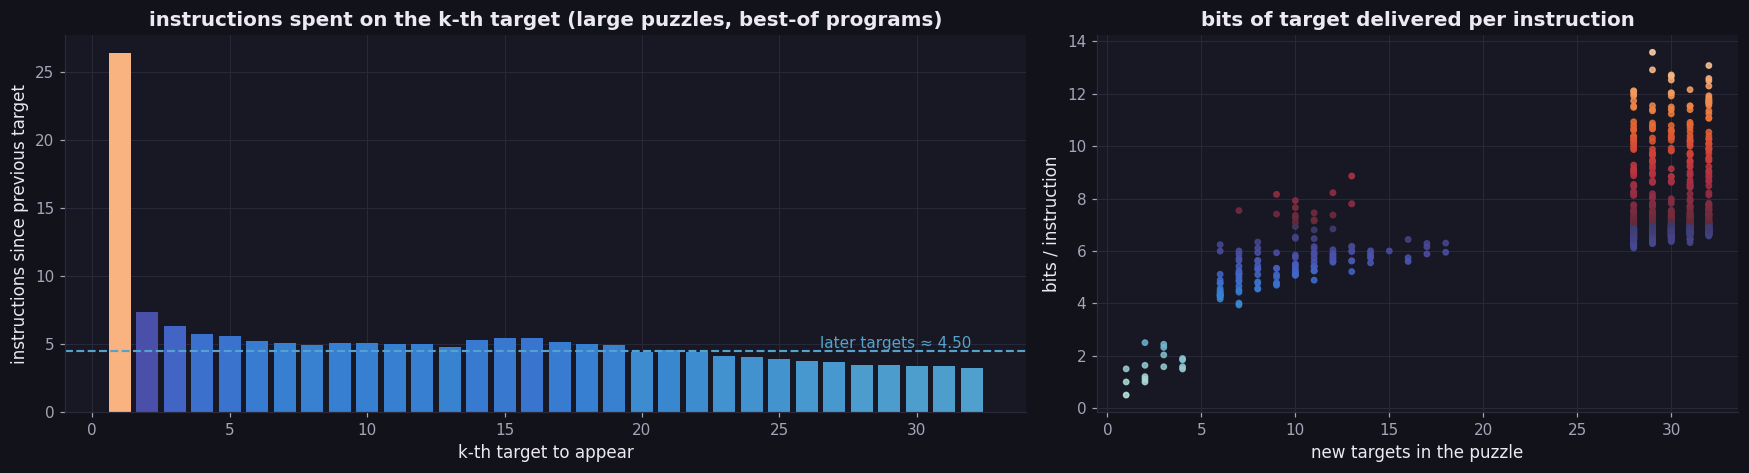

On the large puzzles the **first five targets cost 51.5 instructions together** (10.30 each), while every later target costs about **4.50**. A random 50-bit target needs roughly five operations even from a well-stocked register file, so the later targets are already close to that ceiling — the start of a program is where a new idea pays most.

In [6]:
def first_appearances(puzzle, prog):
    starts, targets, _ = puzzle
    regs = list(starts) + [None] * (48 - len(starts))
    need = set(targets) - set(starts)
    steps = []
    for step, (op, i, j, d) in enumerate(prog, 1):
        a, b = regs[i], regs[j]
        v = a + b if op == "+" else a - b if op == "-" else a * b if op == "*" else a // b
        regs[d] = v
        if v in need:
            need.discard(v)
            steps.append(step)
    return steps

by_rank = defaultdict(list)
bits = []
for pid, (n, prog) in best_of.items():
    s, t, cap = PUZZLES[pid]
    steps = first_appearances(PUZZLES[pid], prog)
    if len(steps) >= 28 and math.log10(t[-1]) >= 13:
        gaps = np.diff([0] + steps)
        for k, g in enumerate(gaps, 1):
            by_rank[k].append(g)
    bits.append((len(set(t) - set(s)), sum(math.log2(x) for x in set(t) - set(s)) / n))
ranks = sorted(k for k in by_rank if len(by_rank[k]) > 50)
mean_gap = np.array([np.mean(by_rank[k]) for k in ranks])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
norm = (mean_gap - mean_gap.min()) / (mean_gap.max() - mean_gap.min())
ax.bar(ranks, mean_gap, color=[ICEFIRE(0.15 + 0.8 * x) for x in norm])
ax.axhline(np.mean(mean_gap[5:]), color=ICE, ls="--", lw=1.4)
ax.text(ranks[-1], np.mean(mean_gap[5:]) + 0.25, f"later targets ≈ {np.mean(mean_gap[5:]):.2f}", ha="right", color=ICE)
ax.set(title="instructions spent on the k-th target (large puzzles, best-of programs)",
       xlabel="k-th target to appear", ylabel="instructions since previous target")
ax = axes[1]
b = np.array(bits)
ax.scatter(b[:, 0], b[:, 1], c=b[:, 1], cmap=ICEFIRE_BRIGHT, s=12, alpha=0.85)
ax.set(title="bits of target delivered per instruction", xlabel="new targets in the puzzle", ylabel="bits / instruction")
plt.tight_layout(); plt.show()

first5 = mean_gap[:5].sum()
display(Markdown(f"On the large puzzles the **first five targets cost {first5:.1f} instructions together** "
                 f"({first5 / 5:.2f} each), while every later target costs about **{np.mean(mean_gap[5:]):.2f}**. "
                 "A random 50-bit target needs roughly five operations even from a well-stocked register file, "
                 "so the later targets are already close to that ceiling — the start of a program is where "
                 "a new idea pays most."))

<div style="border-left:6px solid #377fd0;background:linear-gradient(90deg,rgba(55,127,208,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#377fd0;font-weight:700">5 · optimizer</span><div style="font-size:24px;font-weight:800;margin-top:2px">IceFire: recombine the arithmetic graph, then re-allocate registers</div></div>

A program is really a **graph**: every value has an operator and two parent values. Different banks often
contain programs of the same length for the same puzzle that build *different* intermediate values. The optimizer
pools the values of all equally short programs of a puzzle and lists every way one pooled value can be computed
from two others (`v = a ∘ b`). An exact **CP-SAT** model then chooses

* a set of values that contains every target,
* one recipe for every chosen value whose two operands are chosen too,
* no cycles (each value gets a level above both operands),

minimising the number of chosen values. A small secondary cost keeps the original recipes and their original
order wherever possible, because a value that suddenly depends on a much later one stretches register lifetimes.

The chosen plan is then compiled into the 48 registers. Values are emitted in the original order; a value whose new
recipe needs a later operand is either delayed, or its operand is *pulled* forward just in time — both schedules are
tried. When the bank is full, the value whose next use is farthest away is overwritten (Belady's rule) and rebuilt
from its recipe if it is needed again. The result must be strictly shorter than the best-of program **and** pass
the referee, otherwise the best-of program stays.

In [7]:
REG = 48
INF = 1 << 60


def recipes_of(starts, prog):
    """Values in order of first appearance -> (op, a, b), with a >= b for + and *."""
    regs = list(starts) + [None] * (REG - len(starts))
    rec, sset = {}, set(starts)
    for op, i, j, d in prog:
        a, b = regs[i], regs[j]
        v = a + b if op == "+" else a - b if op == "-" else a * b if op == "*" else a // b
        regs[d] = v
        if v not in rec and v not in sset:
            if op in "+*" and a < b:
                a, b = b, a
            rec[v] = (op, a, b)
    return rec


def prune(starts, targets, rec):
    sset, need, stack = set(starts), set(), [t for t in targets if t not in starts]
    while stack:
        v = stack.pop()
        if v in need or v in sset:
            continue
        need.add(v)
        _, a, b = rec[v]
        stack += [a, b]
    return {v: rec[v] for v in need}


def all_recipes(values, starts, cap):
    vset, vl, out = set(values), sorted(values), []
    for i, a in enumerate(vl):
        for b in vl[: i + 1]:
            s = a + b
            if s in vset and s not in starts and s != a and s != b:
                out.append((s, "+", a, b))
            if a == b:
                if 1 in vset and 1 not in starts and a != 1:
                    out.append((1, "/", a, a))
            else:
                d = a - b
                if d in vset and d not in starts and d != b:
                    out.append((d, "-", a, b))
                if a % b == 0:
                    q = a // b
                    if q in vset and q not in starts and q != a and q != b:
                        out.append((q, "/", a, b))
            p = a * b
            if p <= cap and p in vset and p not in starts and p != a and p != b:
                out.append((p, "*", a, b))
    return out


def cpsat_plan(starts, targets, values, recipes, hint, det_time):
    sset = set(starts)
    nonstart = [v for v in values if v not in sset]
    order = {v: k + 1 for k, v in enumerate(hint)}
    m = cp_model.CpModel()
    x = {v: m.NewBoolVar("") for v in nonstart}
    lvl = {v: m.NewIntVar(0, len(nonstart), "") for v in nonstart}
    by_v, ys, penalty = defaultdict(list), [], []
    for v, op, a, b in recipes:
        y = m.NewBoolVar("")
        by_v[v].append(y)
        ys.append((y, v, op, a, b))
        if hint.get(v) != (op, a, b):
            late = v in order and any(u in order and order[u] > order[v] for u in (a, b))
            penalty.append((3 if late else 1) * y)
        for u in (a, b):
            if u not in sset:
                m.AddImplication(y, x[u])
                m.Add(lvl[v] >= lvl[u] + 1).OnlyEnforceIf(y)
        m.AddHint(y, int(hint.get(v) == (op, a, b)))
    for v in nonstart:
        if by_v[v]:
            m.AddBoolOr(by_v[v]).OnlyEnforceIf(x[v])
        else:
            m.Add(x[v] == 0)
        m.AddHint(x[v], int(v in hint))
        m.AddHint(lvl[v], order.get(v, 0))
    for t in targets:
        if t not in sset:
            m.Add(x[t] == 1)
    m.Minimize(1000 * sum(x.values()) + sum(penalty))
    solver = cp_model.CpSolver()
    solver.parameters.num_workers = 1                  # deterministic
    solver.parameters.random_seed = 0
    solver.parameters.max_deterministic_time = det_time
    solver.parameters.max_time_in_seconds = 30 * det_time
    status = solver.Solve(m)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return None
    plan = {}
    for y, v, op, a, b in ys:
        if v not in plan and solver.Value(x[v]) and solver.Value(y):
            plan[v] = (op, a, b)
    return plan


def schedule(starts, rec, hint_pos, pull):
    sset = set(starts)
    consumers = defaultdict(list)
    for v, (_, a, b) in rec.items():
        consumers[a].append(v)
        if b != a:
            consumers[b].append(v)
    topo, seen = [], set(sset)
    for root in rec:
        stack = [(root, False)]
        while stack:
            v, done = stack.pop()
            if done:
                topo.append(v)
                continue
            if v in seen:
                continue
            seen.add(v)
            stack.append((v, True))
            _, a, b = rec[v]
            stack += [(u, False) for u in (a, b) if u not in seen]
    prio = {}
    for v in reversed(topo):
        cons = [prio[c] for c in consumers.get(v, ()) if c in prio]
        jit = min(cons) - 0.5 if cons else 1e18
        prio[v] = (min(float(hint_pos[v]), jit) if pull else float(hint_pos[v])) if v in hint_pos else jit
    indeg = {v: len({u for u in (a, b) if u not in sset}) for v, (_, a, b) in rec.items()}
    heap = [(prio[v], v) for v, k in indeg.items() if k == 0]
    heapq.heapify(heap)
    seq = []
    while heap:
        _, v = heapq.heappop(heap)
        seq.append(v)
        for c in consumers.get(v, ()):
            indeg[c] -= 1
            if indeg[c] == 0:
                heapq.heappush(heap, (prio[c], c))
    return seq


def compile_plan(starts, targets, rec, hint_pos, pull):
    sset = set(starts)
    rec = prune(starts, targets, rec)
    seq = schedule(starts, rec, hint_pos, pull)
    uses = defaultdict(list)
    for pos, v in enumerate(seq):
        _, a, b = rec[v]
        uses[a].append(pos)
        if b != a:
            uses[b].append(pos)
    ptr = defaultdict(int)

    def next_use(v, pos):
        lst = uses.get(v, ())
        i = ptr[v]
        while i < len(lst) and lst[i] <= pos:
            i += 1
        ptr[v] = i
        return lst[i] if i < len(lst) else INF

    bank, where, prog = [None] * REG, {}, []
    for k, s in enumerate(starts):
        bank[k], where[s] = s, k

    def dest(pos, hard, soft):
        best_r, best_key = -1, -1
        for r in range(REG):
            if r in hard:
                continue
            u = bank[r]
            if u is None:
                return r
            nu = next_use(u, pos)
            if (r in soft and nu != INF) or u in sset:
                continue
            if nu > best_key:
                best_r, best_key = r, nu
                if nu == INF:
                    return r
        return best_r

    def emit(v, pos, hard, depth=0):
        if v in where:
            return where[v]
        if v in sset or depth > 64:
            raise Invalid("cannot rebuild")
        op, a, b = rec[v]
        pre = hard | {where[u] for u in (a, b) if u in where}
        ra = emit(a, pos, pre, depth + 1)
        rb = emit(b, pos, pre | {ra}, depth + 1)
        rd = dest(pos, hard, {ra, rb})
        if rd < 0:
            raise Invalid("register allocation failed")
        if bank[rd] is not None:
            del where[bank[rd]]
        bank[rd], where[v] = v, rd
        prog.append([op, ra, rb, rd])
        return rd

    for pos, v in enumerate(seq):
        emit(v, pos, set())
    return prog


def improve(task):
    """(pid, [(length, program), ...] sorted) -> (pid, length, program or None, plan size)."""
    pid, progs, det_time, max_programs = task
    starts, targets, cap = PUZZLES[pid]
    best_len, best_prog = progs[0]
    hint = prune(starts, targets, recipes_of(starts, best_prog))
    values = set(starts)
    for n, prog in progs[:max_programs]:
        if n == best_len:
            values |= set(recipes_of(starts, prog))
    plan = cpsat_plan(starts, targets, sorted(values), all_recipes(values, set(starts), cap), hint, det_time)
    if not plan or len(plan) >= best_len:
        return pid, best_len, None, len(plan) if plan else None
    hint_pos = {v: k for k, v in enumerate(recipes_of(starts, best_prog))}
    best = (best_len, None)
    for pull in (False, True):
        try:
            prog = compile_plan(starts, targets, plan, hint_pos, pull)
            n = replay(PUZZLES[pid], prog)
        except Invalid:
            continue
        if n < best[0]:
            best = (n, prog)
    return pid, best[0], best[1], len(plan)

In [8]:
DET_TIME, MAX_PROGRAMS = 5.0, 8
tasks = []
for pid in PUZZLES:
    progs = sorted(candidates[pid].values(), key=lambda x: x[0])
    tasks.append((pid, progs, DET_TIME, MAX_PROGRAMS))
tasks.sort(key=lambda t: -t[1][0][0])          # long puzzles first for better load balance

t0 = time.time()
final = {pid: (n, prog) for pid, (n, prog) in best_of.items()}
gains, plan_gain = {}, 0
with mp.get_context("fork").Pool(CPUS) as pool:
    for k, (pid, n, prog, plan) in enumerate(pool.imap_unordered(improve, tasks, chunksize=4), 1):
        if plan is not None:
            plan_gain += max(0, best_of[pid][0] - plan)
        if prog is not None and n < final[pid][0]:
            gains[pid] = final[pid][0] - n
            final[pid] = (n, prog)
        if k % 200 == 0:
            print(f"{k:5d}/{len(tasks)}  improved puzzles {len(gains):3d}  saved {sum(gains.values()):4d}  "
                  f"{time.time() - t0:6.0f}s", flush=True)
FINAL = sum(n for n, _ in final.values())
print(f"plans shorter by {plan_gain} values in total; {sum(gains.values())} instructions survive register "
      f"allocation on {len(gains)} puzzles · {time.time() - t0:.0f}s")

  200/1000  improved puzzles   0  saved    0      74s
  400/1000  improved puzzles   0  saved    0     183s
  600/1000  improved puzzles   1  saved    1     208s
  800/1000  improved puzzles   1  saved    1     232s
 1000/1000  improved puzzles   1  saved    1     280s
plans shorter by 6 values in total; 1 instructions survive register allocation on 1 puzzles · 280s


<div style="border-left:6px solid #ce4338;background:linear-gradient(90deg,rgba(206,67,56,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#ce4338;font-weight:700">6 · submission</span><div style="font-size:24px;font-weight:800;margin-top:2px">Write, read back, replay, score</div></div>

In [9]:
def program_text(prog):
    return "[" + ",".join(f'["{op}",{i},{j},{d}]' for op, i, j, d in prog) + "]"

out = WORK / "submission.csv"
with out.open("w", encoding="utf-8", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "program"])
    for pid in sorted(PUZZLES):
        w.writerow([pid, program_text(final[pid][1])])

check = read_bank(out)
assert check is not None and set(check) == set(PUZZLES)
SCORE = sum(replay(PUZZLES[pid], parse(cell)) for pid, cell in check.items())
assert SCORE == FINAL
cards(card("best public bank", f"{BEST_BANK:,}", "validated, complete"),
      card("best-of", f"{BEST_OF:,}", f"{BEST_BANK - BEST_OF:,} below the best bank", grad=("#3d3b6d", "#672a39")),
      card("IceFire submission", f"{SCORE:,}", f"{BEST_BANK - SCORE:,} below the best public bank",
           grad=("#ce4338", "#f5a36a")))
print(f"{out} · {SCORE:,} instructions · {SCORE / NEW_TARGETS:.3f} per target")

/kaggle/working/submission.csv · 136,052 instructions · 5.058 per target


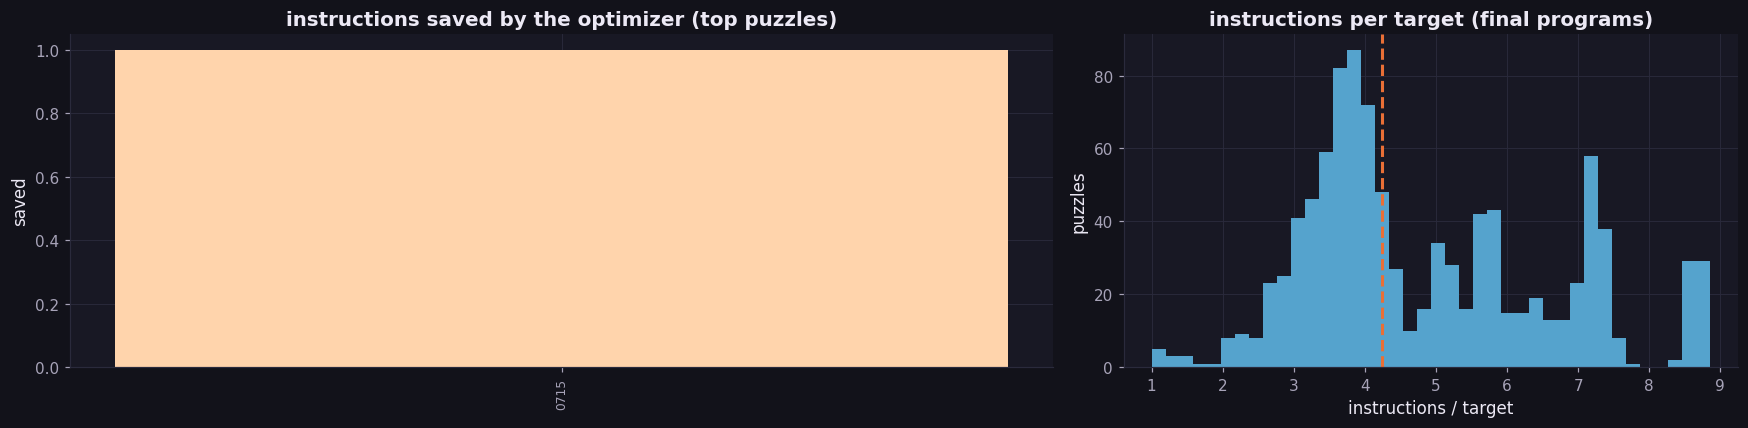

In [10]:
if gains:
    g = pd.Series(gains).sort_values(ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [1.6, 1]})
    ax = axes[0]
    top = g.head(30)
    ax.bar(range(len(top)), top.values, color=icefire(len(top), 1.0, 0.55))
    ax.set_xticks(range(len(top)), top.index.str.replace("scored_", ""), rotation=90, fontsize=8)
    ax.set(title="instructions saved by the optimizer (top puzzles)", ylabel="saved")
    ax = axes[1]
else:
    fig, ax = plt.subplots(figsize=(8, 4))
per_target = [final[p][0] / max(1, len(set(t) - set(s))) for p, (s, t, _) in PUZZLES.items()]
ax.hist(per_target, bins=40, color=ICE)
ax.axvline(np.median(per_target), color=FIRE, lw=2, ls="--")
ax.set(title="instructions per target (final programs)", xlabel="instructions / target", ylabel="puzzles")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #ce4338;background:linear-gradient(90deg,rgba(206,67,56,.16),rgba(31,30,30,0));padding:10px 18px;border-radius:8px;margin-top:8px"><span style="font-size:13px;letter-spacing:3px;text-transform:uppercase;color:#ce4338;font-weight:700">credits</span><div style="font-size:24px;font-weight:800;margin-top:2px">Built on public work — thank you</div></div>

The programs this notebook starts from were found by other Kagglers; the optimizer only recombines and
re-allocates them. If this notebook helps you, please upvote the sources too:

* **Tony Li** — [Elf Calculator With Register Reuse](https://www.kaggle.com/code/tonylica/elf-calculator-with-register-reuse): the backward dictionary search and register reuse that everything else grew from.
* **konbu17** — [Wider Dictionary + Portfolio](https://www.kaggle.com/code/konbu17/santa-2026-wider-dictionary-portfolio-163k): wider dictionaries, register-aware planning, recombination; the attached program dataset.
* **lightningv08** — [Shared Intermediates & CUDA Cofactors](https://www.kaggle.com/code/lightningv08/santa-2026-shared-intermediates-cuda-cofactors) and [CUDA Arithmetic Bridge Search](https://www.kaggle.com/code/lightningv08/santa-2026-cuda-arithmetic-bridge-search).
* **Atakan Aldemir** — [Joint Recipes for Large Puzzles](https://www.kaggle.com/code/atakanaldemir/santa-2026-joint-recipes-for-large-puzzles).
* **Aman Atar** — [Fast Validator, EDA & SOTA Baseline](https://www.kaggle.com/code/amanatar/santa-2026-fast-validator-eda-sota-baseline).
* **Elias T.-H. Shieh** — [Verified Best Programs](https://www.kaggle.com/code/b05204047elias/verified-best-programs-142-856).
* **Ángel Jacinto Sánchez Ruiz** — [Public Merge](https://www.kaggle.com/code/sacuscreed/public-merge).
* **Georgy Mamarin** — [Why the First Target Costs 3x More](https://www.kaggle.com/code/georgymamarin/santa-2026-why-the-first-target-costs-3x-more).
* **Bikram Basnet** — [Arithmetic Graph Rewrites](https://www.kaggle.com/code/bikrambasnet1/santa-2026-arithmetic-graph-rewrites).
* **Hanif Noer Rofiq** — [Verified Portfolio](https://www.kaggle.com/code/hanifnoerrofiq/santa-2026-elf-calculator-verified-portfolio).
* **Nilanjan Saha** — [Best-of-Public Elf Optimizer](https://www.kaggle.com/code/nilanjansaha123/best-of-public-elf-optimizer).
* **lucifer19** — [The Elf Calculator X-Ray](https://www.kaggle.com/code/lucifer19/santa-2026-the-elf-calculator-x-ray).

**Using the output.** The submission is safe to merge with your own programs: replay both files and keep the shorter
valid program per puzzle. To refresh the result, attach newer versions of the banks (or your own submission as a
dataset) and run all cells — the merge, the optimizer and the final replay pick everything up automatically.